
# TP CNN, part 4 : super-resolution [Optional]

Practical work originally created by Alasdair Newson (https://sites.google.com/site/alasdairnewson/)

For any remark or suggestion, please feel free to contact me at:

- loic.lefolgoc@telecom-paris.fr

## Objective:

We want to implement a Convolutional Neural Network (CNN) to do image super-resolution.

## Image super-resolution:

The super-resolution problem can be summarised as follows. We have an image as an input, which is defined over a grid $\{0,1,\dots, m-1\} \times \{0,1,\dots, n-1\}$. We define a factor $\delta$, by which we upsample the image. The output of the super-resolution is an image defined on the grid $\{0,\frac{1}{\delta},\dots, m-1\} \times \{0,\frac{1}{\delta},\dots, n-1\}$.

__IMPORTANT NOTE:__ We set $\delta$ to 2 in this TP, because it is not too difficult to create a network that works with this factor. If you change it, it might be more difficult to create a satisfactory network.

## Model

In this part of the TP, you have complete freedom to create any model you want, as long as the input is an image, and the output is also an image of size $\delta m \times \delta n$. You will have to choose the architecture and loss which seems reasonable to you.

To help you, here is a function to upsample images in neural networks :

- ```from tensorflow.keras.layers import UpSampling2D```

Of course, you can use any upsampling layer you wish.

## Dataset

We will be using the mnist dataset for this part. This is to ensure that you can obtain good results.

__IMPORTANT NOTES:__
- Think carefully about what the training data and labels are in this case, and create them accordingly
- We will use ```n_max=5000``` to limit the number of datapoints (as in part 1) to go faster

# Your task:
You have to load the mnist data (see the first part of the TP), create the model, train it, and evaluate and display the results.

We have created a function ```super_res_interpolate```, which carries out super-resolution using basic interpolation (bilinear or bicubic), with which you can compare your results visually and numerically.



In [1]:

# # Load packages

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

import tensorflow as tf
from tensorflow.keras.utils import to_categorical

from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Dropout, Activation, Flatten, Input
from tensorflow.keras.layers import Conv2D, MaxPooling2D, UpSampling2D
from tensorflow.keras import optimizers
from scipy import interpolate
print(tf.keras.__version__)

3.13.2


We only provide a few cells of code to help you carry out the TP. The rest is up to you !

Linear interpolation, to compare against:

In [2]:
# choice of the interpolation method
interp_method = 'linear'
# upsampling factor
delta = 2
# the maximum number of data to take from mnist (to go a bit faster)
n_max = 5000

# upsample by a factor of delta
# by definition, the new grid has a step size of 1/delta
def super_res_interpolate(imgs_in,delta,interp_method = 'linear'):
	imgs_out = tf.image.resize( tf.constant(imgs_in),\
		[delta*imgs_in.shape[1],delta*imgs_in.shape[2]], method='bilinear').numpy()

	return(imgs_out)


Data import and creation:

In [3]:

# ## Import data
#
# We are going to start with the mnist dataset. The mnist dataset has 10 classes which go from "0" to "9" (all the digits). We are going to truncate the number of elements in the database for faster training. Note that "scalar" means that the class is encoded as a scalar, rather than as a one-hot vector (we do the conversion afterwards).

from tensorflow.keras.datasets import mnist
(X_train, Y_train_scalar), (X_test, Y_test_scalar) = mnist.load_data()

X_train = X_train[0:n_max,:,:]
X_test = X_test[0:n_max,:,:]
Y_train_scalar = Y_train_scalar[0:n_max]
Y_test_scalar = Y_test_scalar[0:n_max]

mnist_label_list = [ '0', '1','2','3','4','5','6','7','8','9']

print(X_train.shape)
print(X_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
(5000, 28, 28)
(5000, 28, 28)


Now, we carry out some data pre-processing. In particular, we normalise the data to the range $[0,1]$ and convert the labels to a one-hot encoding :

In [4]:
# input image dimensions (mnist data is grey-level)
img_rows, img_cols, nb_channels = X_train.shape[1], X_train.shape[2], 1

# In case depth is 1 (black and white pictures) -> reshape to proper format
X_train = X_train.reshape(X_train.shape[0], img_rows, img_cols, nb_channels)
X_test = X_test.reshape(X_test.shape[0], img_rows, img_cols, nb_channels)

X_train = X_train.astype('float32')
X_test = X_test.astype('float32')
X_train /= 255.
X_test /= 255.

# now modify the data for the super-resolution problem

Y_train = X_train.copy()
X_train = X_train[:,::delta,::delta,:]
Y_test = X_test.copy()
X_test = X_test[:,::delta,::delta,:]
img_rows, img_cols, nb_channels = X_train.shape[1], X_train.shape[2], 1
print('X_train shape:', X_train.shape)
print('Y_train shape:', Y_train.shape)

X_train shape: (5000, 14, 14, 1)
Y_train shape: (5000, 28, 28, 1)


Define your own model, train it, and evaluate it on test data:

In [5]:
# ## Defining the model for MNIST

# We define the parameters of the model :
learning_rate = 0.001
n_epochs = 20
batch_size = 64
nb_filters = 64
kernel_size = (3, 3)

# We define the model itself
# Input  : low-resolution image (14 x 14 x 1)
# Output : high-resolution image (28 x 28 x 1)
# Strategy: extract features at low resolution -> upsample by delta -> refine at high resolution
model = Sequential([
    Input(shape=(img_rows, img_cols, nb_channels)),

    # feature extraction at low resolution
    Conv2D(nb_filters, kernel_size, padding='same', activation='relu'),
    Conv2D(nb_filters, kernel_size, padding='same', activation='relu'),

    # upsampling by a factor delta
    UpSampling2D(size=(delta, delta), interpolation='bilinear'),

    # refinement / reconstruction at high resolution
    Conv2D(nb_filters, kernel_size, padding='same', activation='relu'),
    Conv2D(nb_filters // 2, kernel_size, padding='same', activation='relu'),

    # 1 output channel, sigmoid because pixel values are in [0,1]
    Conv2D(nb_channels, kernel_size, padding='same', activation='sigmoid'),
])

# Compile, train and evaluate model
# Loss = MSE between predicted HR image and ground-truth HR image
model.compile(loss='mse',
              optimizer=optimizers.Adam(learning_rate=learning_rate),
              metrics=['mae'])
model.summary()

history = model.fit(X_train, Y_train, batch_size=batch_size, epochs=n_epochs, validation_split=0.1, verbose=1)

score = model.evaluate(X_test, Y_test, verbose=0)
print('Test loss (MSE):', score[0])
print('Test MAE:', score[1])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,249 (364.25 KB)

 Trainable params: 93,249 (364.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 9s 59ms/step - loss: 0.0401 - mae: 0.1002 - val_loss: 0.0091 - val_mae: 0.0331
Epoch 2/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0076 - mae: 0.0287 - val_loss: 0.0071 - val_mae: 0.0276
Epoch 3/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0067 - mae: 0.0262 - val_loss: 0.0067 - val_mae: 0.0264
Epoch 4/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0063 - mae: 0.0251 - val_loss: 0.0069 - val_mae: 0.0262
Epoch 5/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0060 - mae: 0.0244 - val_loss: 0.0062 - val_mae: 0.0248
Epoch 6/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0057 - mae: 0.0236 - val_loss: 0.0059 - val_mae: 0.0243
Epoch 7/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0056 - mae: 0.0231 - val_loss: 0.0058 - val_mae: 0.0237
Epoch 8/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0055 - mae: 0.0227 - val_loss: 0.0056 - val_mae: 0.0230
Epoch 9/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.005

Visualize some results from ```model```, compared to linear interpolation:

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 599ms/step


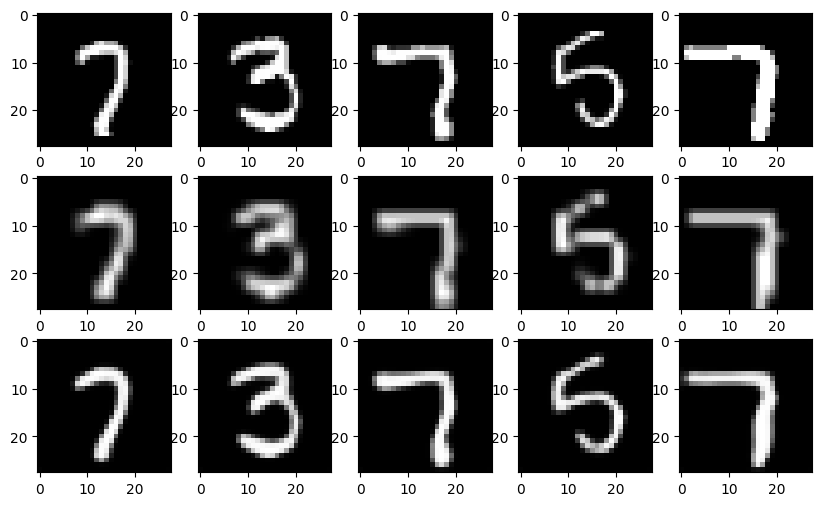

In [6]:
n_samples = 5

rand_ind = np.random.randint(0,X_test.shape[0],n_samples)
in_data = X_test[rand_ind,:,:]
ground_truth = Y_test[rand_ind,:,:]
out_data_cnn = model.predict(in_data)
out_data_interp = super_res_interpolate(in_data,delta)
plt.figure(figsize=(10, 6))
for idx in range(0,n_samples):

	plt.subplot(3, n_samples, idx+1)
	plt.imshow(ground_truth[idx,:,:,:].squeeze(),cmap='gray')
	plt.subplot(3, n_samples, idx+n_samples+1)
	plt.imshow(out_data_interp[idx,:,:,:].squeeze(),cmap='gray')
	plt.subplot(3, n_samples, idx+2*n_samples+1)
	plt.imshow(out_data_cnn[idx,:,:,:].squeeze(),cmap='gray')

MSE error of linear interpolation method, to compare to MSE error of proposed model:

In [7]:

def evaluate_super_res_interpolate(X_test,Y_test,delta,interp_method):
  mse_out = (((super_res_interpolate(X_test,delta,interp_method) -  Y_test)**2).sum())
  mse_out /= np.prod(X_test.shape[0:3])
  return(mse_out)

Comparison:

In [8]:
# evaluate results

mse_interpolate = evaluate_super_res_interpolate(X_test,Y_test,delta,interp_method)
print('Test loss interpolation:', mse_interpolate)

score = model.evaluate(X_test, Y_test, verbose=False)
print('Test loss CNN:', score[0])


Test loss interpolation: 0.09081398278061224
Test loss CNN: 0.004752926994115114
